# Notebook 04 - Exploratory Data Analysis

## Objetivo

Observar las distribuciones y relaciones entre las diferentes variables

## Entrada
- `data/processed/data_processed.csv`

In [8]:
## Inicialización

import pandas as pd
from matplotlib import pyplot as plt

In [9]:
# Cargar archivos de datos

processed_path = '../data/processed/' 
df = pd.read_csv(processed_path+'dataset_processed.csv')#v, parse_dates=['begin_date'])

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   senior_citizen      7043 non-null   object 
 1   partner             7043 non-null   object 
 2   dependents          7043 non-null   object 
 3   type                7043 non-null   object 
 4   paperless_billing   7043 non-null   object 
 5   payment_method      7043 non-null   object 
 6   monthly_charges     7043 non-null   float64
 7   internet_service    7043 non-null   object 
 8   online_security     7043 non-null   object 
 9   online_backup       7043 non-null   object 
 10  device_protection   7043 non-null   object 
 11  tech_support        7043 non-null   object 
 12  streaming_tv        7043 non-null   object 
 13  streaming_movies    7043 non-null   object 
 14  multiple_lines      7043 non-null   object 
 15  months_as_customer  7043 non-null   int64  
 16  churn 

In [11]:
churn_pct = df.groupby('churn')["churn"].count()
churn_pct = churn_pct/churn_pct.sum() *100
print(churn_pct)

churn
0    73.463013
1    26.536987
Name: churn, dtype: float64


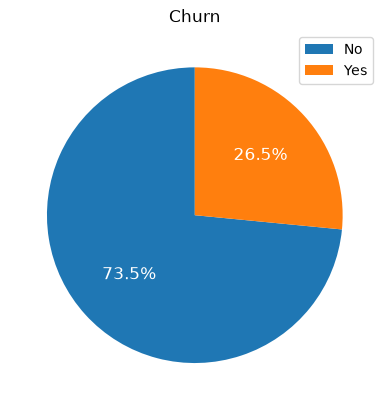

In [12]:
# Mostrar balance de clases de churn

fig, ax = plt.subplots()
pie= ax.pie(df.groupby('churn')["churn"].count(),
       startangle=90
       )
ax.pie_label(pie, "{frac:.1%}", textprops={'fontsize': 'large', 'color': 'white'})
ax.set_title("Churn")
ax.legend(['No','Yes'])
plt.show()

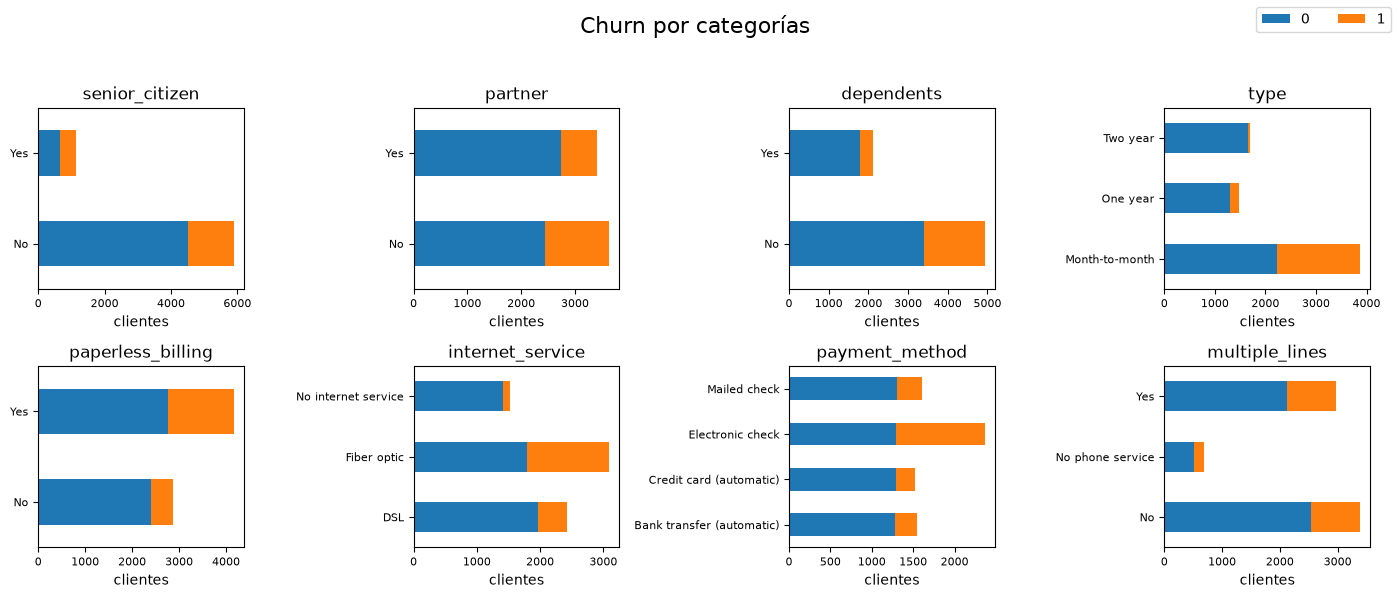

In [13]:
# Mostrar la relación de ciertas variables seleccionadas con el churn

names = ['senior_citizen', 'partner', 'dependents', 'type',
         'paperless_billing', 'internet_service', 'payment_method', 'multiple_lines']

fig, axs = plt.subplots(2, 4, figsize=(14,6))
for k, name in enumerate(names):
    ax = axs[k//4][k%4]
    df2 = df.groupby([name,'churn'])['churn'].count().unstack()
    df2.plot.barh(ax=ax, stacked=True, legend=False)
    ax.set_title(name, fontsize=12)
    ax.tick_params(axis='y', labelsize=8)
    ax.tick_params(axis='x', labelsize=8)
    ax.set_xlabel("clientes")
    ax.set_ylabel("")

# Leyenda global única
fig.legend(df2.columns, loc='upper right', ncol=2, fontsize=10)
fig.suptitle("Churn por categorías", fontsize = 16)
plt.tight_layout(rect=[0,0,1,0.95])
plt.show()

Destaca el impacto sobre el churn de las variables *type*, *payment_method* e *internet_service*. 

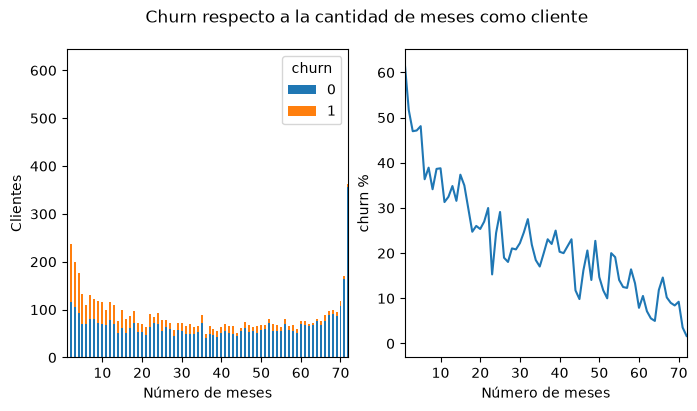

In [14]:
# Observar la proporción de churn respecto al tiempo como cliente
max_months = df['months_as_customer'].max()
fig, axs = plt.subplots(1,2, figsize = (8,4))
fig.suptitle("Churn respecto a la cantidad de meses como cliente")
ax=axs[0]
dft = df.groupby(['months_as_customer', 'churn'])['churn'].count().unstack()
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_xticks(range(0,max_months+1,10))
ax.tick_params(axis='x', rotation=0)
ax.set_xlim(1,max_months)
ax.set_xlabel('Número de meses')
ax.set_ylabel("Clientes")
ax=axs[1]
dft = df.groupby('months_as_customer')['churn'].mean()*100
dft.plot(kind='line', ax=ax)
ax.set_xticks(range(0,max_months+1,10))
ax.tick_params(axis='x', rotation=0)
ax.set_xlim(1,max_months)
ax.set_xlabel('Número de meses')
ax.set_ylabel("churn %")
plt.show()

Durante los primeros meses el porcentaje de churn es bastante alto, superando el 50% pero la tendencia es decreciente para clientes con mayor antigüedad.

C:\Users\RCorrea\AppData\Local\Temp\ipykernel_24360\485236993.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churn_pct=df2.groupby('charges_bin')['churn'].mean()*100


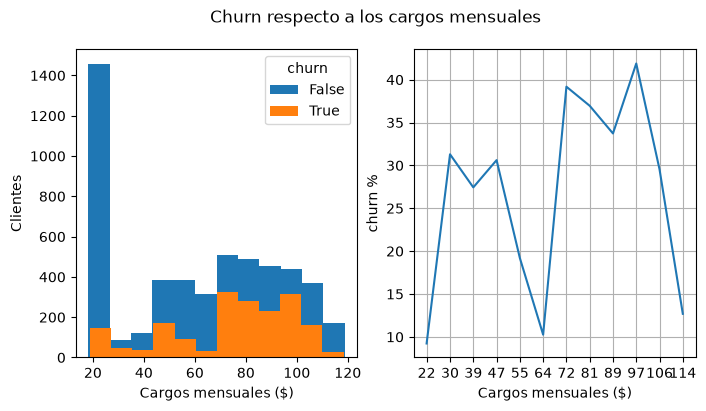

In [15]:
# Observar la proporción de churn respecto a los cargos mensuales
fig, axs = plt.subplots(1,2, figsize = (8,4))
fig.suptitle("Churn respecto a los cargos mensuales")
bins = 12
ax=axs[0]
df[df['churn']==False]['monthly_charges'].plot(
    kind='hist', bins = bins, alpha=1, label='No churn', ax = ax)
df[df['churn']==True]['monthly_charges'].plot(
    kind='hist', bins = bins, alpha=1, label='Churn', ax = ax)
ax.legend(["False", "True"], title="churn")
ax.tick_params(axis='x', rotation=0)
ax.set_xlabel('Cargos mensuales ($)')
ax.set_ylabel("Clientes")

ax=axs[1]
df2 = df[['monthly_charges','churn']].copy()
df2['charges_bin'], bin_edges = pd.cut(df2['monthly_charges'], bins=bins, retbins=True)
bin_centers = [(bin_edges[k]+bin_edges[k+1])/2 for k in range(len(bin_edges)-1)]
churn_pct=df2.groupby('charges_bin')['churn'].mean()*100
ax.plot(bin_centers, churn_pct.values)#, kind='line', ax = ax)
ax.set_xticks(bin_centers)
ax.set_xticklabels([str(int(b)) for b in bin_centers])
ax.tick_params(axis='x', rotation=0)
ax.set_xlabel('Cargos mensuales ($)')
ax.set_ylabel("churn %")
ax.grid()
plt.show()

Los clientes con cargos más bajos y más altos tienen un churn muy bajo

### Resumen del análisis exploratorio

- Se realizaron imputaciones de valores ausentes.
- Mayormente representa clientes que no contrataron servicio de internet.
- Se calcula la cantidad de meses que ha permanecido el cliente.
- El 26.5% de los clientes han dejado la compañía
- Se detectaron casos donde hay un mayor churn respecto a las demás categorías:
  1. Los clientes que tienen un contrato mensua.
  2. Los clientes que tienen internet por fibra óptica.
  3. Los clientes que pagan por cheque electrónico.
- A mayor tiempo como cliente mejor proporción de churn.
